<a href="https://colab.research.google.com/github/furalmiqbadi/PCVK26_01_AbdulGhofurAlmiqbadi/blob/main/Week10_01.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Persiapan


In [3]:
import cv2 as cv
import numpy as np
import os
from matplotlib import pyplot as plt

print("OpenCV versi:", cv.__version__)


OpenCV versi: 5.0.0


In [4]:
from google.colab import drive
drive.mount('/content/drive')


Mounted at /content/drive


In [2]:
PATH = '/content/drive/MyDrive/3-Tugas/PCVK'

IMG = '/content/drive/MyDrive/3-Tugas/PCVK/images'

## D1.2 - Template Matching (6 Metode OpenCV)



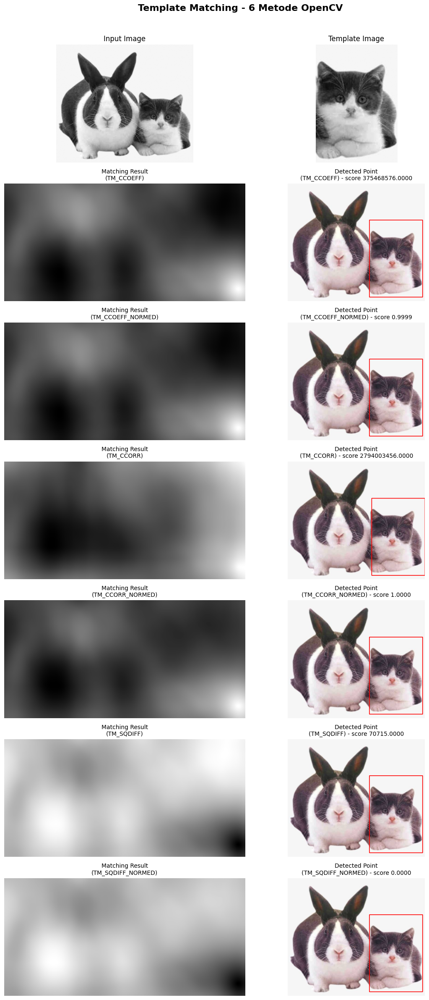

In [ ]:
img = cv.imread(PATH + '/cats_and_bunnies.jpg')
template = cv.imread(PATH + '/cat_template.jpg')

img_gray = cv.cvtColor(img, cv.COLOR_BGR2GRAY)
template_gray = cv.cvtColor(template, cv.COLOR_BGR2GRAY)

h, w = template_gray.shape

# 6 metode
methods = ['TM_CCOEFF', 'TM_CCOEFF_NORMED', 'TM_CCORR',
           'TM_CCORR_NORMED', 'TM_SQDIFF', 'TM_SQDIFF_NORMED']

# output
fig, axes = plt.subplots(7, 2, figsize=(12, 24))
fig.suptitle('Template Matching - 6 Metode OpenCV', fontsize=16, fontweight='bold', y=0.99)

axes[0, 0].imshow(img_gray, cmap='gray')
axes[0, 0].set_title('Input Image', fontsize=12)
axes[0, 0].axis('off')

axes[0, 1].imshow(template_gray, cmap='gray')
axes[0, 1].set_title('Template Image', fontsize=12)
axes[0, 1].axis('off')

for idx, method in enumerate(methods):
    method_const = getattr(cv, method)

    res = cv.matchTemplate(img_gray, template_gray, method_const)

    min_val, max_val, min_loc, max_loc = cv.minMaxLoc(res)

    if method in ['TM_SQDIFF', 'TM_SQDIFF_NORMED']:
        top_left = min_loc
        score = min_val
    else:
        top_left = max_loc
        score = max_val

    bottom_right = (top_left[0] + w, top_left[1] + h)

    output = img.copy()
    cv.rectangle(output, top_left, bottom_right, (0, 0, 255), 2)

    axes[idx+1, 0].imshow(res, cmap='gray')
    axes[idx+1, 0].set_title(f'Matching Result\n({method})', fontsize=10)
    axes[idx+1, 0].axis('off')

    axes[idx+1, 1].imshow(cv.cvtColor(output, cv.COLOR_BGR2RGB))
    axes[idx+1, 1].set_title(f'Detected Point\n({method}) - score {score:.4f}', fontsize=10)
    axes[idx+1, 1].axis('off')

plt.tight_layout(rect=[0, 0, 1, 0.98])
plt.show()


## D1.3 - Template Matching Manual (Multiple Object)


In [ ]:
def template_matching_manual(source, template, threshold=0.8):
    s_h, s_w = source.shape
    t_h, t_w = template.shape
    R = np.zeros((s_h - t_h + 1, s_w - t_w + 1))

    for i in range(R.shape[0]):
        for j in range(R.shape[1]):
            patch = source[i:i+t_h, j:j+t_w]

            num = np.sum((patch - patch.mean()) * (template - template.mean()))
            den = np.sqrt(np.sum((patch - patch.mean())**2) *
                          np.sum((template - template.mean())**2))
            R[i, j] = num / den if den != 0 else 0

    locations = np.where(R >= threshold)
    return locations, (t_w, t_h)


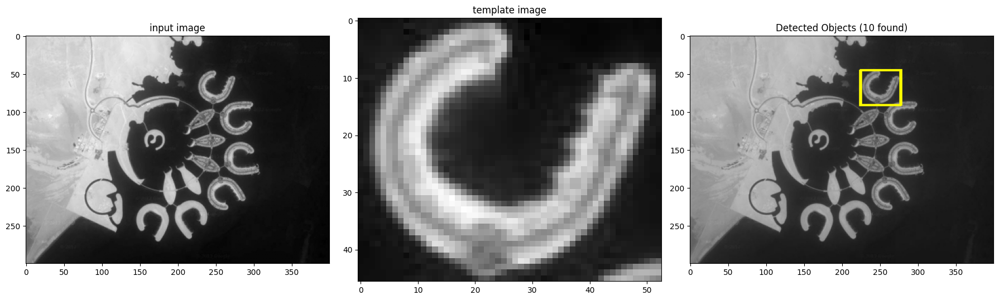

In [ ]:
source = cv.imread(PATH + '/bahrain.jpg', 0)
template = cv.imread(PATH + '/bahrain_template.jpg', 0)

locs, (tw, th) = template_matching_manual(source, template, threshold=0.85)

output = cv.cvtColor(source, cv.COLOR_GRAY2BGR)

for pt in zip(*locs[::-1]):
    cv.rectangle(output, pt, (pt[0]+tw, pt[1]+th), (0, 255, 255), 1)

plt.figure(figsize=(18, 6))

plt.subplot(131)
plt.imshow(source, cmap='gray')
plt.title('input image', fontsize=12)
plt.axis('on')

plt.subplot(132)
plt.imshow(template, cmap='gray')
plt.title('template image', fontsize=12)
plt.axis('on')

plt.subplot(133)
plt.imshow(cv.cvtColor(output, cv.COLOR_BGR2RGB))
plt.title(f'Detected Objects ({len(locs[0])} found)', fontsize=12)
plt.axis('on')

plt.tight_layout()
plt.show()


## D1.4 - Edge Detection (Sobel, Canny, Laplacian)


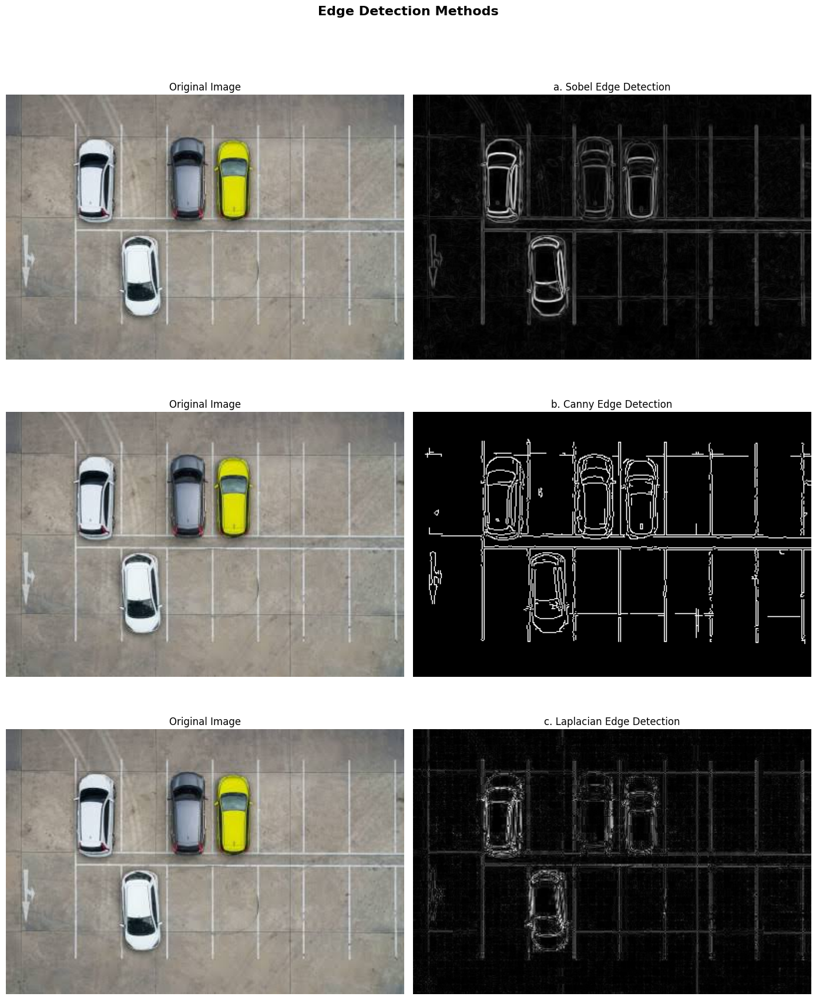

In [ ]:
img = cv.imread(PATH + '/car_park.jpg')
gray = cv.cvtColor(img, cv.COLOR_BGR2GRAY)

sobelx = cv.Sobel(gray, cv.CV_64F, 1, 0, ksize=3)
sobely = cv.Sobel(gray, cv.CV_64F, 0, 1, ksize=3)
sobel_mag = np.sqrt(sobelx**2 + sobely**2)
sobel_mag = np.uint8(sobel_mag / sobel_mag.max() * 255)

canny = cv.Canny(gray, 100, 200)

laplacian = cv.Laplacian(gray, cv.CV_64F)
laplacian = np.uint8(np.absolute(laplacian))

fig, axes = plt.subplots(3, 2, figsize=(14, 18))
fig.suptitle('Edge Detection Methods', fontsize=16, fontweight='bold')

axes[0, 0].imshow(cv.cvtColor(img, cv.COLOR_BGR2RGB))
axes[0, 0].set_title('Original Image', fontsize=12)
axes[0, 0].axis('off')
axes[0, 1].imshow(sobel_mag, cmap='gray')
axes[0, 1].set_title('a. Sobel Edge Detection', fontsize=12)
axes[0, 1].axis('off')

axes[1, 0].imshow(cv.cvtColor(img, cv.COLOR_BGR2RGB))
axes[1, 0].set_title('Original Image', fontsize=12)
axes[1, 0].axis('off')
axes[1, 1].imshow(canny, cmap='gray')
axes[1, 1].set_title('b. Canny Edge Detection', fontsize=12)
axes[1, 1].axis('off')

axes[2, 0].imshow(cv.cvtColor(img, cv.COLOR_BGR2RGB))
axes[2, 0].set_title('Original Image', fontsize=12)
axes[2, 0].axis('off')
axes[2, 1].imshow(laplacian, cmap='gray')
axes[2, 1].set_title('c. Laplacian Edge Detection', fontsize=12)
axes[2, 1].axis('off')

plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()


## D1.5 - Corner Detection (Harris & Shi-Tomasi)

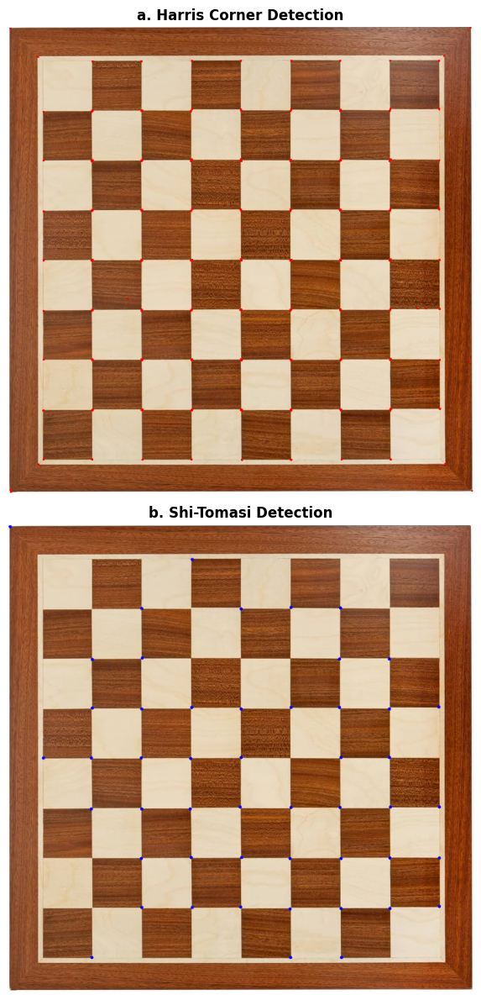

In [ ]:
img = cv.imread(PATH + '/chess_board.jpg')
gray = cv.cvtColor(img, cv.COLOR_BGR2GRAY)
gray_float = np.float32(gray)

# a. Harris Corner Detection
dst = cv.cornerHarris(gray_float, blockSize=2, ksize=3, k=0.04)
dst = cv.dilate(dst, None)

threshold_harris = 0.05 * dst.max()

harris_img = img.copy()
harris_img[dst > threshold_harris] = [0, 0, 255]

# b. Shi-Tomasi Detection
corners = cv.goodFeaturesToTrack(gray, maxCorners=50, qualityLevel=0.1, minDistance=10)

shi_img = img.copy()
if corners is not None:
    corners = np.intp(corners)
    for c in corners:
        x, y = c.ravel()
        cv.circle(shi_img, (x, y), 3, (255, 0, 0), -1)

plt.figure(figsize=(10, 12))

plt.subplot(211)
plt.imshow(cv.cvtColor(harris_img, cv.COLOR_BGR2RGB))
plt.title('a. Harris Corner Detection', fontsize=12, fontweight='bold')
plt.axis('off')

plt.subplot(212)
plt.imshow(cv.cvtColor(shi_img, cv.COLOR_BGR2RGB))
plt.title('b. Shi-Tomasi Detection', fontsize=12, fontweight='bold')
plt.axis('off')

plt.tight_layout()
plt.show()


## D1.6 - Hough Transform (Grid Detection)

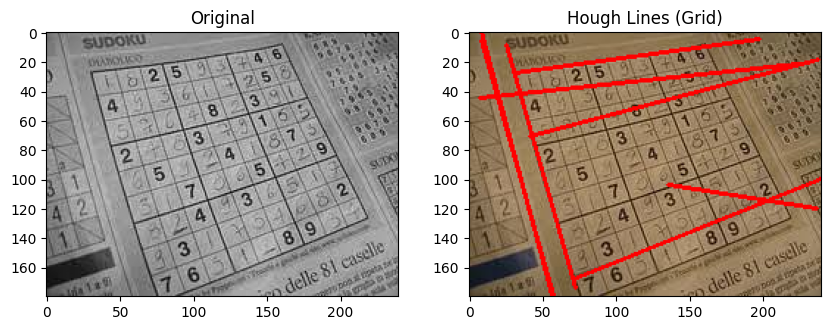

Jumlah garis terdeteksi: 105


In [ ]:
img = cv.imread(PATH + '/sudoku.jpg')
gray = cv.cvtColor(img, cv.COLOR_BGR2GRAY)

edges = cv.Canny(gray, 50, 150, apertureSize=3)

kernel = np.ones((3, 3), np.uint8)
dilated = cv.dilate(edges, kernel, iterations=1)
eroded = cv.erode(dilated, kernel, iterations=1)

lines = cv.HoughLinesP(eroded, 1, np.pi/180,
                       threshold=100,
                       minLineLength=80,
                       maxLineGap=10)

output = img.copy()

if lines is not None:
    for line in lines:
        if len(line) == 4:
            x1, y1, x2, y2 = line
        else:
            x1, y1, x2, y2 = line[0]

        angle = np.arctan2(y2 - y1, x2 - x1) * 180 / np.pi

        is_horizontal = abs(angle) < 25 or abs(angle) > 155
        is_vertical = 65 < abs(angle) < 115

        if is_horizontal or is_vertical:
            cv.line(output, (x1, y1), (x2, y2), (0, 0, 255), 2)

plt.figure(figsize=(10, 5))
plt.subplot(121), plt.imshow(gray, cmap='gray'), plt.title('Original')
plt.subplot(122), plt.imshow(cv.cvtColor(output, cv.COLOR_BGR2RGB)), plt.title('Hough Lines (Grid)')
plt.show()

print(f"Jumlah garis terdeteksi: {len(lines) if lines is not None else 0}")


## D1.7 - Contour Detection


Total kontur: 13
Kontur besar (area > 10000): 2


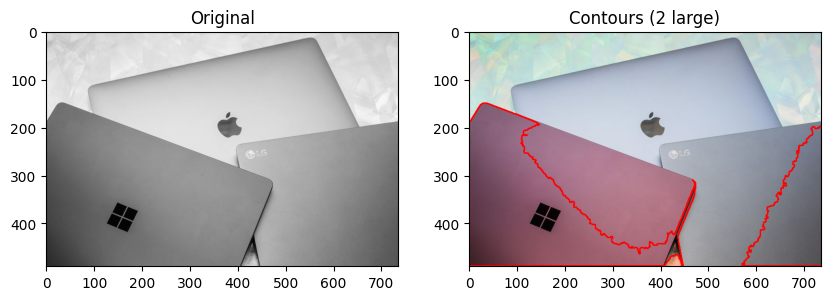

In [ ]:
img = cv.imread(PATH + '/laptop.jpg')
gray = cv.cvtColor(img, cv.COLOR_BGR2GRAY)

blurred = cv.GaussianBlur(gray, (5, 5), 0)

_, binary = cv.threshold(blurred, 127, 255, cv.THRESH_BINARY_INV)

contours, hierarchy = cv.findContours(binary, cv.RETR_EXTERNAL, cv.CHAIN_APPROX_SIMPLE)

large_contours = [c for c in contours if cv.contourArea(c) > 10000]

print(f"Total kontur: {len(contours)}")
print(f"Kontur besar (area > 10000): {len(large_contours)}")

output = img.copy()
cv.drawContours(output, large_contours, -1, (0, 0, 255), 2)  # merah tipis

plt.figure(figsize=(10, 5))
plt.subplot(121), plt.imshow(gray, cmap='gray'), plt.title('Original')
plt.subplot(122), plt.imshow(cv.cvtColor(output, cv.COLOR_BGR2RGB)), plt.title(f'Contours ({len(large_contours)} large)')
plt.show()


## D2.8 - Face Detection (Haar Cascade)



In [ ]:
import sys, shutil, subprocess, importlib

FIX_DIR = "/content/opencv_fix"
shutil.rmtree(FIX_DIR, ignore_errors=True)

subprocess.run([sys.executable, "-m", "pip", "install", "-q",
                "--no-cache-dir", "--target=" + FIX_DIR, "--no-deps",
                "opencv-python-headless<5"], check=False)

sys.path.insert(0, FIX_DIR)

for m in [m for m in list(sys.modules) if m == "cv2" or m.startswith("cv2.")]:
    del sys.modules[m]
importlib.invalidate_caches()

import cv2 as cv

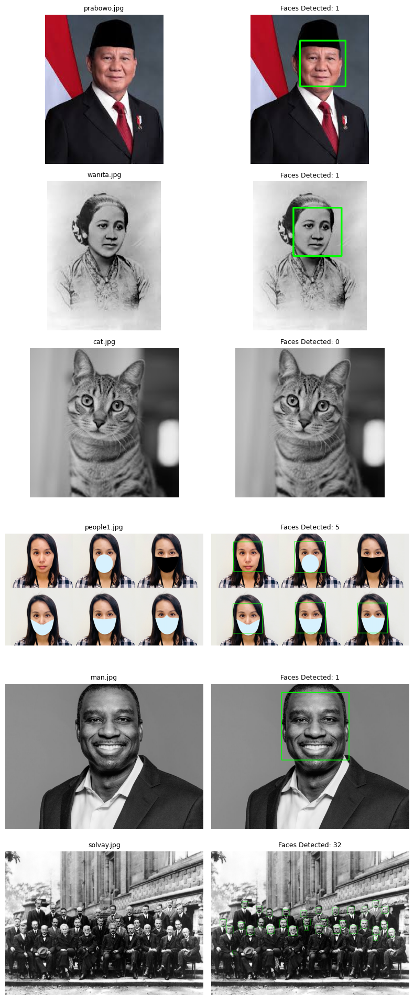

In [ ]:
cascade_wajah = cv.CascadeClassifier(IMG + '/haarcascades/haarcascade_frontalface_alt.xml')

if cascade_wajah.empty():
    cascade_wajah = cv.CascadeClassifier(cv.data.haarcascades + 'haarcascade_frontalface_alt.xml')

facedet_dir = IMG + '/facedet'
daftar = [os.path.join(facedet_dir, f) for f in [
    'prabowo.jpg', 'wanita.jpg', 'cat.jpg',
    'people1.jpg', 'man.jpg', 'solvay.jpg',
]]

hilang = [p for p in daftar if not os.path.exists(p)]
if hilang:
    print('File tidak ditemukan:')
    for p in hilang:
        print('  ', os.path.basename(p))
    daftar = [p for p in daftar if os.path.exists(p)]

if not daftar:
    raise FileNotFoundError('Tidak ada gambar yang cocok di ' + facedet_dir)

fig, axes = plt.subplots(len(daftar), 2, figsize=(8, 3.2 * len(daftar)))
axes = np.atleast_2d(axes)

for baris, path_img in enumerate(daftar):
    img = cv.imread(path_img)
    gray = cv.cvtColor(img, cv.COLOR_BGR2GRAY)

    roi_wajah = cascade_wajah.detectMultiScale(gray, scaleFactor=1.1,
                                               minNeighbors=5, minSize=(30, 30))

    output = img.copy()
    for (x, y, w, h) in roi_wajah:
        cv.rectangle(output, (x, y), (x+w, y+h), (0, 255, 0), 2)

    axes[baris, 0].imshow(cv.cvtColor(img, cv.COLOR_BGR2RGB))
    axes[baris, 0].set_title(os.path.basename(path_img), fontsize=9)
    axes[baris, 0].axis('off')

    axes[baris, 1].imshow(cv.cvtColor(output, cv.COLOR_BGR2RGB))
    axes[baris, 1].set_title(f'Faces Detected: {len(roi_wajah)}', fontsize=9)
    axes[baris, 1].axis('off')

plt.tight_layout()
plt.show()

## D2.9 - Cat Face Detection


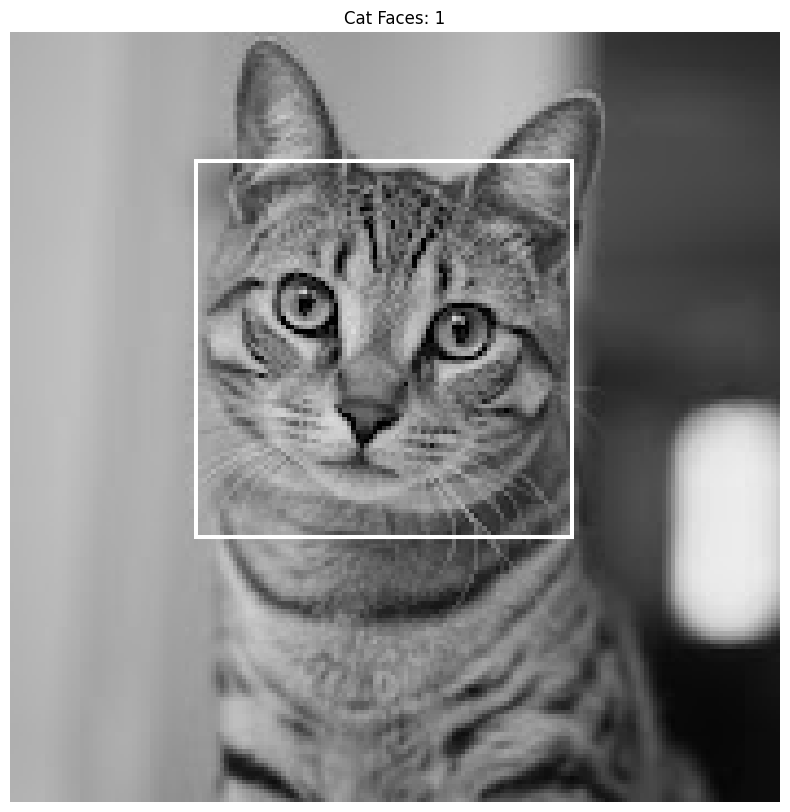

In [ ]:
cat_cascade = cv.CascadeClassifier(cv.data.haarcascades + 'haarcascade_frontalcatface.xml')
cat_extended = cv.CascadeClassifier(cv.data.haarcascades + 'haarcascade_frontalcatface_extended.xml')

img = cv.imread(IMG + '/facedet/cat.jpg')
gray = cv.cvtColor(img, cv.COLOR_BGR2GRAY)

pad = 40
gray_pad = cv.copyMakeBorder(gray, pad, pad, pad, pad, cv.BORDER_REPLICATE)

def deteksi(cascade):
    if cascade.empty():
        return []
    return cascade.detectMultiScale(gray_pad, scaleFactor=1.05,
                                    minNeighbors=3, minSize=(30, 30))

cats = deteksi(cat_cascade)
if len(cats) == 0:
    hasil_extended = deteksi(cat_extended)
    if len(hasil_extended) > 0:
        cats = hasil_extended

for (x, y, w, h) in cats:
    cv.rectangle(img, (x - pad, y - pad), (x - pad + w, y - pad + h), (255, 255, 255), 1)

plt.figure(figsize=(10, 10))
plt.imshow(cv.cvtColor(img, cv.COLOR_BGR2RGB))
plt.title(f'Cat Faces: {len(cats)}')
plt.axis('off')
plt.show()

## D2.10 - Eye Detection


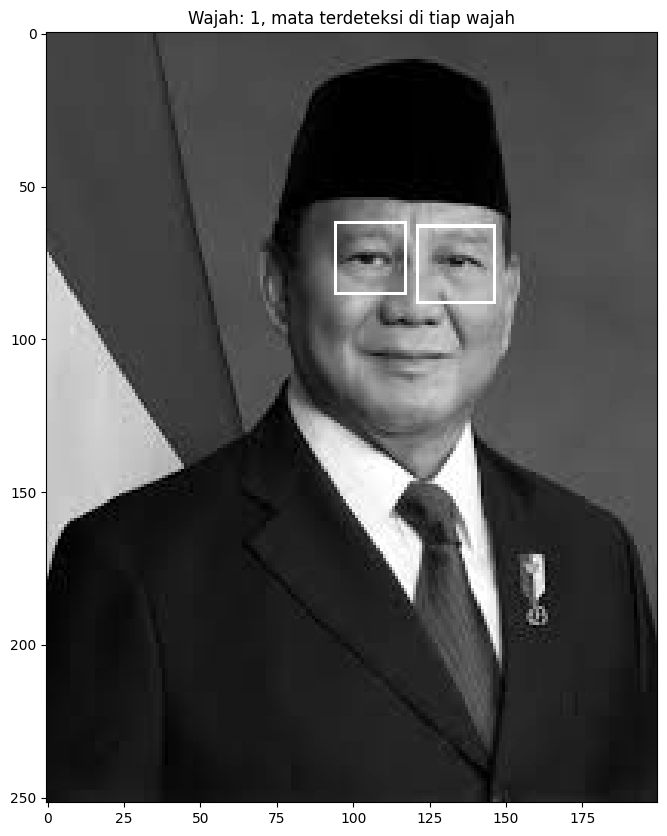

In [ ]:
# D2.10 - Eye Detection
face_cascade = cv.CascadeClassifier(cv.data.haarcascades + 'haarcascade_frontalface_alt.xml')
eye_cascade = cv.CascadeClassifier(cv.data.haarcascades + 'haarcascade_eye.xml')
eye_glasses = cv.CascadeClassifier(cv.data.haarcascades + 'haarcascade_eye_tree_eyeglasses.xml')

# Grayscale, seperti pada modul
img = cv.imread(IMG + '/facedet/prabowo.jpg', 0)
faces = face_cascade.detectMultiScale(img, scaleFactor=1.1, minNeighbors=5, minSize=(30, 30))

for (x, y, w, h) in faces:

    # Mata selalu di bagian atas wajah -> batasi ROI sampai 60% tinggi wajah
    roi = img[y:y + int(h * 0.6), x:x+w]

    eyes = eye_cascade.detectMultiScale(roi, scaleFactor=1.05,
                                        minNeighbors=3, minSize=(15, 15))

    # Kalau tetap kurang dari 2, coba cascade khusus kacamata
    if len(eyes) < 2 and not eye_glasses.empty():
        alternatif = eye_glasses.detectMultiScale(roi, scaleFactor=1.05,
                                                  minNeighbors=3, minSize=(15, 15))
        if len(alternatif) > len(eyes):
            eyes = alternatif

    for (ex, ey, ew, eh) in eyes:
        cv.rectangle(img, (x+ex, y+ey), (x+ex+ew, y+ey+eh), 255, 1)

plt.figure(figsize=(10, 10))
plt.imshow(img, cmap='gray')
plt.title(f'Wajah: {len(faces)}, mata terdeteksi di tiap wajah')
plt.show()

## D2.11 - Smile Detection


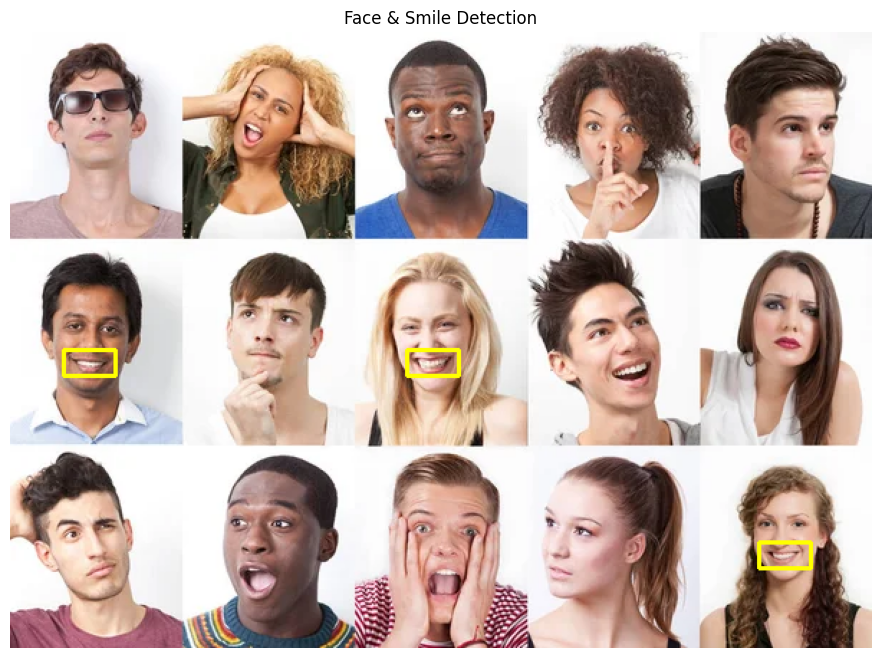

In [ ]:
face_cascade = cv.CascadeClassifier(cv.data.haarcascades + 'haarcascade_frontalface_default.xml')
smile_cascade = cv.CascadeClassifier(cv.data.haarcascades + 'haarcascade_smile.xml')

img = cv.imread(IMG + '/facedet/people_smile.jpg')

gray = cv.cvtColor(img, cv.COLOR_BGR2GRAY)
faces = face_cascade.detectMultiScale(gray, 1.3, 5)

for (x, y, w, h) in faces:

    y0 = y + int(h * 0.45)
    roi_gray = gray[y0:y+h, x:x+w]

    smiles = smile_cascade.detectMultiScale(roi_gray, scaleFactor=1.3,
                                            minNeighbors=15, minSize=(15, 15))

    if len(smiles) == 0:
        roi_gray = gray[y:y+h, x:x+w]
        y0 = y
        smiles = smile_cascade.detectMultiScale(roi_gray, scaleFactor=1.3,
                                                minNeighbors=10, minSize=(15, 15))

    for (sx, sy, sw, sh) in smiles:
        cv.rectangle(img, (x+sx, y0+sy), (x+sx+sw, y0+sy+sh), (0, 255, 255), 2)

plt.figure(figsize=(12, 8))
plt.imshow(cv.cvtColor(img, cv.COLOR_BGR2RGB))
plt.title('Face & Smile Detection')
plt.axis('off')
plt.show()

## D2.12 - Face Tracking (Kamera Google Colab)


<IPython.core.display.Javascript object>

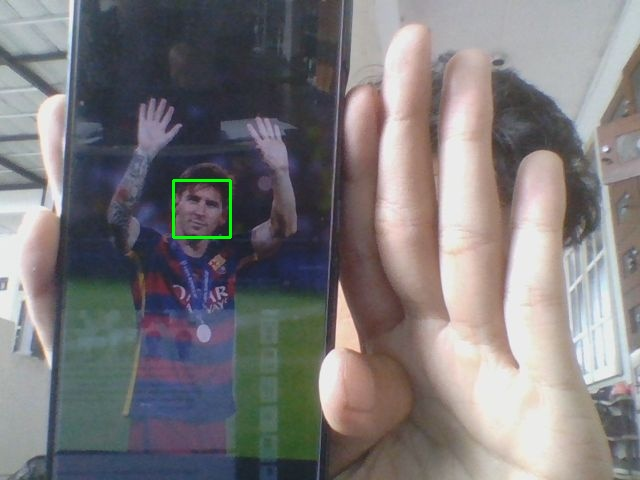

In [ ]:
from IPython.display import display, Javascript, Image
from google.colab.output import eval_js
import base64
import time

display(Javascript('''
(async () => {
  if (window.__stream) { window.__stream.getTracks().forEach(t => t.stop()); }
  if (window.__video) { window.__video.remove(); }

  const video = document.createElement('video');
  video.width = 640;
  video.height = 480;
  video.style.display = 'none';
  document.body.appendChild(video);

  const stream = await navigator.mediaDevices.getUserMedia({video: true});
  video.srcObject = stream;
  await video.play();

  const canvas = document.createElement('canvas');
  canvas.width = 640;
  canvas.height = 480;

  window.__video = video;
  window.__stream = stream;
  window.__canvas = canvas;
})();
'''))

GRAB_FRAME = '''
(function() {
  const v = window.__video;
  if (!v || !v.videoWidth) { return null; }
  const c = window.__canvas;
  c.getContext('2d').drawImage(v, 0, 0, c.width, c.height);
  return c.toDataURL('image/jpeg', 0.8);
})()
'''

STOP_CAMERA = '''
(function() {
  if (window.__stream) { window.__stream.getTracks().forEach(t => t.stop()); }
  if (window.__video) { window.__video.remove(); }
  window.__stream = null;
  window.__video = null;
  window.__canvas = null;
  return true;
})()
'''

def b64_to_frame(data_url):
    header, b64 = data_url.split(',', 1)
    arr = np.frombuffer(base64.b64decode(b64), np.uint8)
    return cv.imdecode(arr, cv.IMREAD_COLOR)


def frame_to_jpeg(frame):
    ok, buf = cv.imencode('.jpg', frame)
    return buf.tobytes()

face_cascade = cv.CascadeClassifier(cv.data.haarcascades + 'haarcascade_frontalface_default.xml')

DURASI = 20

frame = None
for _ in range(20):
    data = eval_js(GRAB_FRAME)
    if data:
        frame = b64_to_frame(data)
        break
    time.sleep(0.5)

tampilan = display(Image(data=frame_to_jpeg(frame)), display_id=True)

mulai = time.time()
jumlah_frame = 0
wajah_terakhir = 0

try:
    while time.time() - mulai < DURASI:
        data = eval_js(GRAB_FRAME)
        if not data:
            continue

        frame = b64_to_frame(data)
        gray = cv.cvtColor(frame, cv.COLOR_BGR2GRAY)

        faces = face_cascade.detectMultiScale(gray, scaleFactor=1.1,
                                              minNeighbors=5, minSize=(30, 30))

        for (x, y, w, h) in faces:
            cv.rectangle(frame, (x, y), (x+w, y+h), (0, 255, 0), 2)

        tampilan.update(Image(data=frame_to_jpeg(frame)))

        jumlah_frame += 1
        wajah_terakhir = len(faces)
finally:
    eval_js(STOP_CAMERA)

## D2.13 - Face Blurring


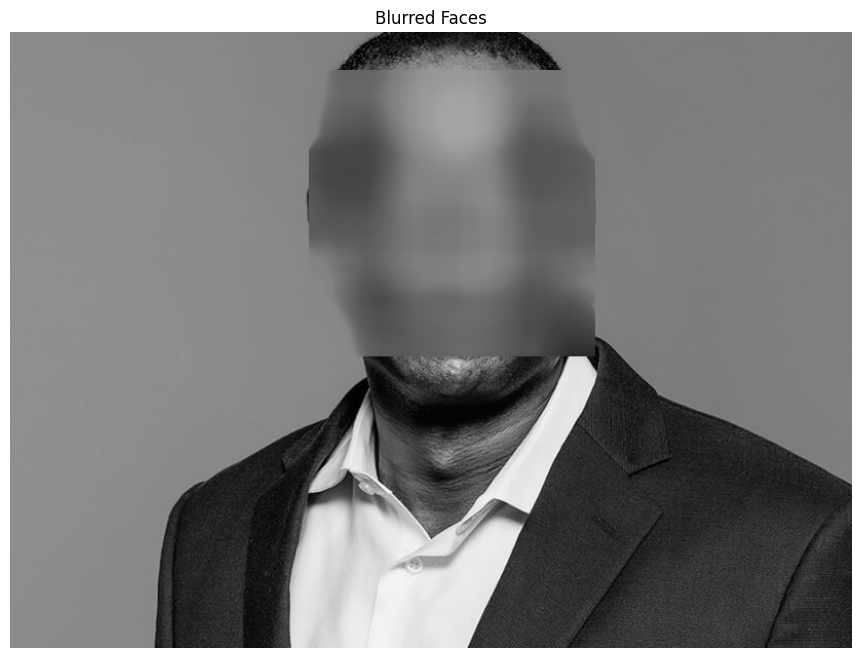

In [ ]:
cascade = cv.CascadeClassifier(cv.data.haarcascades + 'haarcascade_frontalface_alt.xml')

img = cv.imread(IMG + '/facedet/man.jpg')

gray = cv.cvtColor(img, cv.COLOR_BGR2GRAY)
faces = cascade.detectMultiScale(gray, scaleFactor=1.1, minNeighbors=5)

for (x, y, w, h) in faces:
    roi = img[y:y+h, x:x+w]
    ksize = 99
    batas = min(roi.shape[0], roi.shape[1])
    if ksize >= batas:
        ksize = max(3, (batas // 2) * 2 - 1)
    blurred = cv.medianBlur(roi, ksize)
    img[y:y+h, x:x+w] = blurred

plt.figure(figsize=(12, 8))
plt.imshow(cv.cvtColor(img, cv.COLOR_BGR2RGB))
plt.title('Blurred Faces')
plt.axis('off')
plt.show()

## D2.14 - Deteksi Obyek KTM dengan Feature Matching


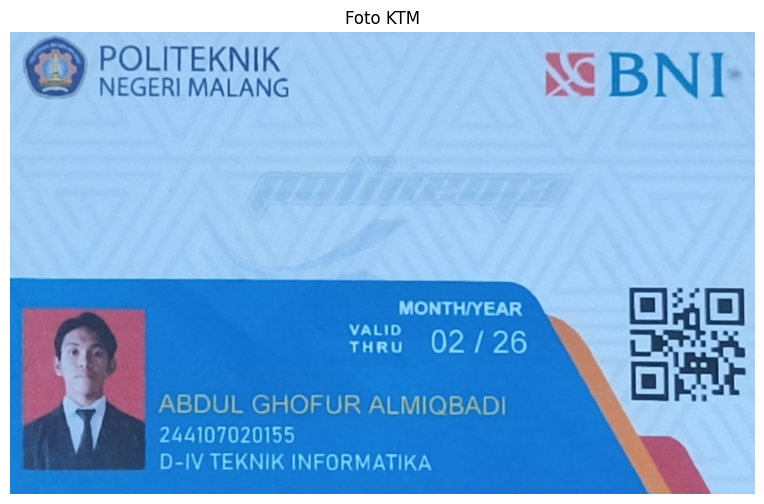

In [ ]:
ktm = cv.imread(PATH + '/KTM1d.jpg')

plt.figure(figsize=(10, 6))
plt.imshow(cv.cvtColor(ktm, cv.COLOR_BGR2RGB))
plt.title('Foto KTM')
plt.axis('off')
plt.show()

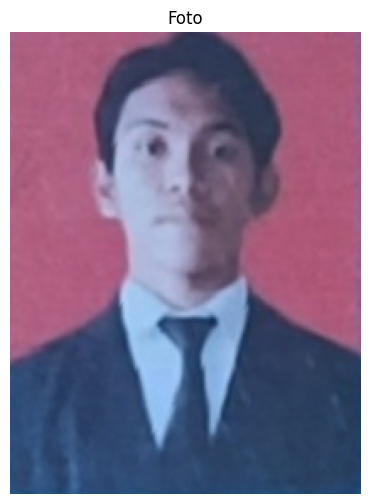

In [ ]:
foto = cv.imread(PATH +  '/foto1.jpg')

else:
    plt.figure(figsize=(10, 6))
    plt.imshow(cv.cvtColor(foto, cv.COLOR_BGR2RGB))
    plt.title('Foto')
    plt.axis('off')
    plt.show()

### b. Feature Matching dengan ORB

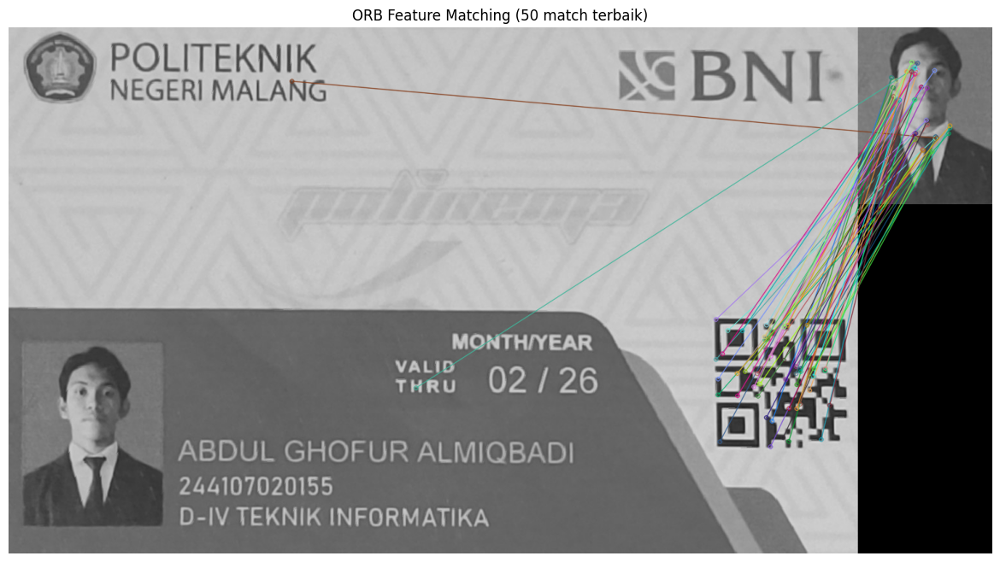

In [ ]:
img1 = cv.imread(PATH + '/KTM1d.jpg', 0)
img2 = cv.imread(PATH + '/foto1.jpg', 0)

orb = cv.ORB_create(nfeatures=1000)
kp1, des1 = orb.detectAndCompute(img1, None)
kp2, des2 = orb.detectAndCompute(img2, None)

bf = cv.BFMatcher(cv.NORM_HAMMING, crossCheck=True)
matches = sorted(bf.match(des1, des2), key=lambda x: x.distance)

output = cv.drawMatches(img1, kp1, img2, kp2, matches[:50], None, flags=2)
plt.figure(figsize=(15, 8))
plt.imshow(output, cmap='gray')
plt.title('ORB Feature Matching (50 match terbaik)')
plt.axis('off')
plt.show()

### c. Feature Matching dengan SIFT + Ratio Test


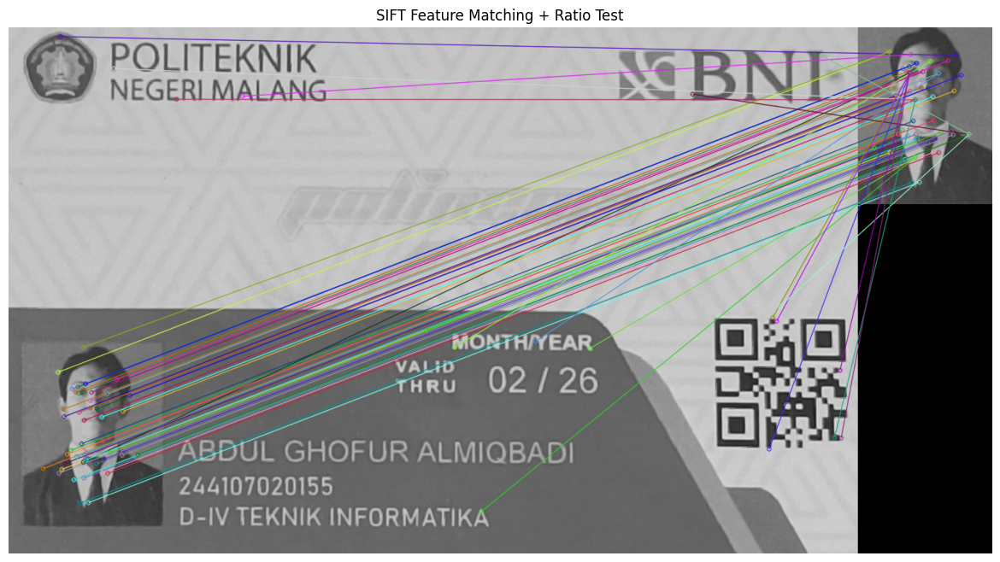

In [ ]:
img1 = cv.imread(PATH + '/KTM1d.jpg', 0)
img2 = cv.imread(PATH + '/foto1.jpg', 0)

sift = cv.SIFT_create()
kp1, des1 = sift.detectAndCompute(img1, None)
kp2, des2 = sift.detectAndCompute(img2, None)

bf = cv.BFMatcher(cv.NORM_L2)
matches = bf.knnMatch(des1, des2, k=2)

good = []
for m, n in matches:
    if m.distance < 0.75 * n.distance:
        good.append(m)

output = cv.drawMatches(img1, kp1, img2, kp2, good, None, flags=2)
plt.figure(figsize=(15, 8))
plt.imshow(output)
plt.title('SIFT Feature Matching + Ratio Test')
plt.axis('off')
plt.show()


## D3 — Pengenalan Karakter KTM dengan CNN


In [5]:
import pickle
from tqdm import tqdm

# Folder dataset karakter KTM (satu subfolder per karakter: 0..9, A..Z)
DATADIR = os.path.join(PATH, 'dataset', 'training')
width, height = 100, 100


def status_folder(folder):
    """'tidak_ada' | 'kosong' | 'siap'"""
    if not os.path.isdir(folder):
        return 'tidak_ada'
    sub = [d for d in os.listdir(folder)
           if os.path.isdir(os.path.join(folder, d))]
    if not sub:
        return 'kosong'
    jumlah_gambar = sum(len(os.listdir(os.path.join(folder, d))) for d in sub)
    return 'siap' if jumlah_gambar > 0 else 'kosong'


status = status_folder(DATADIR)
print('DATADIR :', DATADIR)
print('status  :', status)

if status == 'siap':
    dirs = sorted(d for d in os.listdir(DATADIR)
                  if os.path.isdir(os.path.join(DATADIR, d)))
    training_data = []

    for char_name in dirs:
        char_path = os.path.join(DATADIR, char_name)
        class_number = dirs.index(char_name)
        print(f'  kelas {char_name}: {len(os.listdir(char_path))} gambar')

        for img_name in tqdm(os.listdir(char_path), desc=char_name):
            img_array = cv.imread(os.path.join(char_path, img_name),
                                  cv.IMREAD_GRAYSCALE)
            if img_array is None:
                continue
            training_data.append([cv.resize(img_array, (width, height)),
                                  class_number])

    random.shuffle(training_data)
    X = np.array([f for f, _ in training_data]).reshape(-1, width, height, 1)
    Y = np.array([l for _, l in training_data])
    print('sumber data: folder', DATADIR)

else:
    if status == 'kosong':
        print('Folder ADA, tetapi belum berisi gambar (subfolder 0..9 kosong).')
    else:
        print('Folder TIDAK ADA.')
    print('-> memakai dataset MNIST sebagai pengganti')

    dirs = [str(i) for i in range(10)]

    try:
        from keras.datasets import mnist
        (x_train, y_train), (x_test, y_test) = mnist.load_data()

        # Ambil sebagian saja agar training cepat di Colab
        x_train, y_train = x_train[:12000], y_train[:12000]
        x_test, y_test = x_test[:2000], y_test[:2000]

    except Exception as e:
        print('MNIST gagal diunduh (', e, ') -> memakai sklearn digits')
        from sklearn.datasets import load_digits
        digits = load_digits()
        x_train = digits.images[:1500]
        y_train = digits.target[:1500]
        x_test = digits.images[1500:]
        y_test = digits.target[1500:]

    X = np.array([cv.resize(im, (width, height)) for im in x_train])
    X = X.reshape(-1, width, height, 1)
    Y = np.array(y_train)

    # Data uji disimpan untuk Cell C
    X_test = np.array([cv.resize(im, (width, height)) for im in x_test])
    X_test = X_test.reshape(-1, width, height, 1)
    pickle.dump(X_test, open('X_test.pickle', 'wb'))
    pickle.dump(np.array(y_test), open('Y_test.pickle', 'wb'))

pickle.dump(X,    open("X.pickle", "wb"))
pickle.dump(Y,    open("Y.pickle", "wb"))
pickle.dump(dirs, open("kelas.pickle", "wb"))

print("jumlah data :", len(X))
print("jumlah kelas:", len(dirs), dirs)


DATADIR : /content/drive/MyDrive/3-Tugas/PCVK/dataset/training
status  : kosong
Folder ADA, tetapi belum berisi gambar (subfolder 0..9 kosong).
-> memakai dataset MNIST sebagai pengganti
11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step
jumlah data : 12000
jumlah kelas: 10 ['0', '1', '2', '3', '4', '5', '6', '7', '8', '9']


### Cell B — Training CNN

In [8]:
import pickle
from keras.layers import (Input, Conv2D, MaxPooling2D,
                          Flatten, Dense, ZeroPadding2D)
from keras.models import Model
from keras.optimizers import Adam
from keras.utils import to_categorical

X = pickle.load(open("X.pickle", "rb"))
Y = pickle.load(open("Y.pickle", "rb"))

Y = to_categorical(Y)
X = X / 255.0
width, height = 100, 100
jumlah_kelas = Y.shape[1]

inputs     = Input(shape=(width, height, 1))
conv_layer = ZeroPadding2D(padding=(2, 2))(inputs)
conv_layer = Conv2D(16, (5, 5), strides=(1, 1), activation='relu')(conv_layer)
conv_layer = MaxPooling2D((2, 2))(conv_layer)
conv_layer = Conv2D(32, (3, 3), strides=(1, 1), activation='relu')(conv_layer)
conv_layer = Conv2D(32, (3, 3), strides=(1, 1), activation='relu')(conv_layer)
conv_layer = MaxPooling2D((2, 2))(conv_layer)
conv_layer = Conv2D(64, (3, 3), strides=(1, 1), activation='relu')(conv_layer)

flaten   = Flatten()(conv_layer)
fc_layer = Dense(256, activation='relu')(flaten)
fc_layer = Dense(64,  activation='relu')(fc_layer)
outputs  = Dense(jumlah_kelas, activation='softmax')(fc_layer)

model = Model(inputs=inputs, outputs=outputs)
model.compile(optimizer=Adam(learning_rate=0.0001),
              loss='categorical_crossentropy',
              metrics=['accuracy'])

riwayat = model.fit(X, Y, epochs=5, verbose=1, validation_split=0.2)
model.save('anpr.keras')

print("akurasi training  :", riwayat.history['accuracy'][-1])
print("akurasi validasi  :", riwayat.history['val_accuracy'][-1])


Epoch 1/5
300/300 ━━━━━━━━━━━━━━━━━━━━ 156s 514ms/step - accuracy: 0.8615 - loss: 0.5102 - val_accuracy: 0.9317 - val_loss: 0.2286
Epoch 2/5
300/300 ━━━━━━━━━━━━━━━━━━━━ 153s 511ms/step - accuracy: 0.9532 - loss: 0.1575 - val_accuracy: 0.9596 - val_loss: 0.1449
Epoch 3/5
300/300 ━━━━━━━━━━━━━━━━━━━━ 199s 500ms/step - accuracy: 0.9742 - loss: 0.0861 - val_accuracy: 0.9721 - val_loss: 0.0947
Epoch 4/5
300/300 ━━━━━━━━━━━━━━━━━━━━ 150s 501ms/step - accuracy: 0.9851 - loss: 0.0470 - val_accuracy: 0.9679 - val_loss: 0.1143
Epoch 5/5
300/300 ━━━━━━━━━━━━━━━━━━━━ 150s 501ms/step - accuracy: 0.9908 - loss: 0.0299 - val_accuracy: 0.9712 - val_loss: 0.1126
akurasi training  : 0.9908333420753479
akurasi validasi  : 0.9712499976158142


### Cell C — Testing

In [11]:
import os
import cv2 as cv
import pickle
import numpy as np
import tensorflow as tf

width, height = 100, 100

model = tf.keras.models.load_model("anpr.keras")
dirs  = pickle.load(open("kelas.pickle", "rb"))   # urutan kelas saat training

TESTDIR = os.path.join(PATH, 'dataset', 'testing')

if os.path.isdir(TESTDIR) and os.listdir(TESTDIR):
    # Setiap subfolder = satu karakter, isinya citra karakter tersebut
    benar, total = 0, 0

    for label in sorted(os.listdir(TESTDIR)):
        folder = os.path.join(TESTDIR, label)
        if not os.path.isdir(folder):
            continue

        for nama in sorted(os.listdir(folder)):
            img_array = cv.imread(os.path.join(folder, nama),
                                  cv.IMREAD_GRAYSCALE)
            if img_array is None:
                continue

            arr = cv.resize(img_array, (width, height))
            arr = arr.reshape(-1, width, height, 1) / 255.0
            hasil = dirs[np.argmax(model.predict(arr, verbose=0)[0])]

            total += 1
            benar += int(hasil == label)

    print(f'akurasi data uji: {benar}/{total} = {benar / max(total, 1):.2%}')

else:
    X_test = pickle.load(open('X_test.pickle', 'rb')) / 255.0
    Y_test = pickle.load(open('Y_test.pickle', 'rb'))

    prediksi = np.argmax(model.predict(X_test, verbose=0), axis=1)
    akurasi = float(np.mean(prediksi == Y_test))
    print(f'akurasi data uji: {akurasi:.2%}')

    print('contoh 10 prediksi:')
    for i in range(10):
        print(f'  prediksi {prediksi[i]} | label {Y_test[i]}')


akurasi data uji: 96.25%
contoh 10 prediksi:
  prediksi 7 | label 7
  prediksi 2 | label 2
  prediksi 1 | label 1
  prediksi 0 | label 0
  prediksi 4 | label 4
  prediksi 1 | label 1
  prediksi 4 | label 4
  prediksi 9 | label 9
  prediksi 5 | label 5
  prediksi 9 | label 9
